<div align="center">

[![Open In Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/israaait/cc-ci-partiea/blob/main/CC_Partie_C_S7_ENCG_Setta-AITBOUSALEMISRAA.ipynb)

**[Consulter le dépôt GitHub](https://github.com/israaait/cc-ci-partiea)**

</div>

---


# Étude comparative de 29 algorithmes de Machine Learning

**ENCG Settat — Semestre 7 | Commerce International**  
**Étudiante :** Ait Bousalem Israa  
**Année universitaire :** 2026–2027

Ce notebook présente les principaux algorithmes de régression, de classification, de clustering, de réduction de dimension et d’apprentissage par renforcement. Il combine des rappels théoriques, des schémas de fonctionnement, des applications possibles et des expérimentations Python.

Les expérimentations supervisées et non supervisées s’appuient sur des jeux de données disponibles dans `scikit-learn`. Les parties consacrées aux bandits et à l’apprentissage par renforcement utilisent des environnements simulés.

Les résultats affichés correspondent aux exécutions conservées dans le notebook. Les cellules de code sont organisées dans l’ordre des algorithmes présentés.

In [ ]:
# Sources réelles intégrées à scikit-learn : trois problèmes différents
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes, load_breast_cancer, load_wine
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, f1_score, roc_auc_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
GRAINE = 42

jeu_regression = load_diabetes()
X_reg, y_reg = jeu_regression.data, jeu_regression.target
jeu_classification = load_breast_cancer()
X_cls, y_cls = jeu_classification.data, jeu_classification.target
jeu_non_supervise = load_wine()
X_clu = StandardScaler().fit_transform(jeu_non_supervise.data)  # Exploration sans cible

Xr_ent, Xr_test, yr_ent, yr_test = train_test_split(X_reg, y_reg, test_size=.25, random_state=GRAINE)
Xc_ent, Xc_test, yc_ent, yc_test = train_test_split(X_cls, y_cls, test_size=.25, stratify=y_cls, random_state=GRAINE)
print('Diabetes:', X_reg.shape, '| Breast Cancer:', X_cls.shape, '| Wine:', X_clu.shape)
print('Ces données sont réelles ; les étiquettes du vin ne sont pas employées dans le clustering.')


Diabetes: (442, 10) | Breast Cancer: (569, 30) | Wine: (178, 13)
Ces données sont réelles ; les étiquettes du vin ne sont pas employées dans le clustering.


## 1. Régression linéaire

### C1 — Présentation
La régression linéaire est un algorithme d’apprentissage supervisé de type régression.
Elle reçoit une matrice de variables explicatives X et une cible numérique y, puis prédit une valeur continue.
Son hypothèse principale est que la relation entre les variables et la cible peut être approchée par une combinaison linéaire.
Le modèle associe un coefficient à chaque variable et un biais à l’ensemble.
Pendant l’apprentissage, il choisit ces valeurs pour minimiser la somme des erreurs quadratiques.
Après apprentissage, il calcule une prédiction pour toute nouvelle observation.
Le **paramètre appris** est le vecteur des coefficients β ainsi que le biais β₀.
Dans `LinearRegression`, l’hyperparamètre `fit_intercept` indique si le biais doit être estimé.
Une équation du modèle est : **ŷ = β₀ + β₁x₁ + … + βₚxₚ**.
Ici, ŷ est la valeur prédite, β₀ le biais, βⱼ le coefficient de la variable j, xⱼ sa valeur et p le nombre de variables.

### C2 — Schéma original
```text
INITIALISATION                 APPRENTISSAGE                         SORTIE
Données X, y                   Calcul des prédictions                Nouvelle observation x
      │                        ŷ = Xβ + β₀                                  │
      ▼                              │                                     ▼
Choix d'un modèle linéaire ──► Calcul des erreurs y - ŷ ───────────► ŷ = β₀ + Xβ
                                     │
                                     ▼
                           Minimisation de l'erreur
                           quadratique (moindres carrés)
                                     │
                                     ▼
                         Coefficients β et biais β₀ appris
```
Le schéma illustre le critère des moindres carrés : le modèle cherche la droite ou l’hyperplan qui minimise les erreurs quadratiques.

### C3 — Contextes et choix
- **Finance/gestion :** estimer les dépenses mensuelles d’une entreprise à partir du chiffre d’affaires, des effectifs et des coûts d’activité.
- **Commerce/logistique :** prévoir le volume de ventes à partir du prix, des promotions et de la saisonnalité.
- **Données attendues :** observations sous forme de tableau, variables explicatives numériques (ou encodées) et cible quantitative.
- **Concurrent :** Ridge, qui ajoute une pénalisation pour limiter les coefficients trop élevés.
- **Mauvais choix :** relation fortement non linéaire, présence de valeurs extrêmes influentes ou dépendances complexes non représentées.
- **Métriques :** MAE pour exprimer l’erreur moyenne dans l’unité de la cible ; RMSE pour pénaliser davantage les grandes erreurs ; R² pour mesurer la part de variance expliquée. Elles évaluent une régression et ne se comparent pas aux métriques de classification.

### C4 — Test de sensibilité et interprétation
L’algorithme `LinearRegression` possède peu d’hyperparamètres de réglage. On teste ici `fit_intercept=True` contre `fit_intercept=False`. La comparaison est faite sur un jeu de validation extrait de l’entraînement ; le jeu de test reste réservé à l’évaluation finale. La cellule affiche les MAE et R² réellement calculés.

In [ ]:
from sklearn.linear_model import LinearRegression
modele = LinearRegression().fit(Xr_ent, yr_ent)
predictions = modele.predict(Xr_test)
print('MAE régression linéaire :', round(mean_absolute_error(yr_test, predictions), 2))
print('R² :', round(r2_score(yr_test, predictions), 3))

MAE régression linéaire : 41.55
R² : 0.485


In [ ]:
# C4 — Sensibilité : présence ou absence du biais (validation, pas le test)
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

Xr_train_c4, Xr_val_c4, yr_train_c4, yr_val_c4 = train_test_split(
    Xr_ent, yr_ent, test_size=0.20, random_state=GRAINE
)
for intercept in [True, False]:
    m = LinearRegression(fit_intercept=intercept).fit(Xr_train_c4, yr_train_c4)
    p = m.predict(Xr_val_c4)
    print(f"fit_intercept={intercept} | MAE={mean_absolute_error(yr_val_c4, p):.2f} | R²={r2_score(yr_val_c4, p):.3f}")
print("Interprétation : comparer les deux sorties. Une seule séparation ne permet pas de conclure à une supériorité générale ; répéter avec plusieurs graines.")


fit_intercept=True | MAE=47.66 | R²=0.453
fit_intercept=False | MAE=174.44 | R²=-4.550
Interprétation : comparer les deux sorties. Une seule séparation ne permet pas de conclure à une supériorité générale ; répéter avec plusieurs graines.


## 2. Ridge

### C1 — Présentation
Ridge est un algorithme supervisé de régression linéaire régularisée.
Il reçoit des variables explicatives X et une cible quantitative y et produit des prédictions numériques.
Il suppose que la relation peut être représentée par une combinaison linéaire, mais limite l’amplitude des coefficients.
Il minimise l’erreur quadratique à laquelle il ajoute une pénalité L2.
Cette pénalité réduit généralement la variance du modèle et stabilise les coefficients lorsque les variables sont corrélées.
Le **paramètre appris** est le vecteur de coefficients β et le biais β₀.
L’**hyperparamètre** principal est α (`alpha`) : il règle la force de la pénalisation.
L’équation de l’objectif est : **J(β) = Σᵢ(yᵢ − β₀ − xᵢᵀβ)² + αΣⱼβⱼ²**.
yᵢ est la cible réelle, xᵢ le vecteur des variables de l’observation i, β les coefficients, β₀ le biais et α la régularisation.
Quand α augmente, les coefficients sont davantage rapprochés de zéro, mais ils ne sont généralement pas annulés exactement.

### C2 — Schéma original
```text
INITIALISATION              APPRENTISSAGE                         SORTIE
X, y + choix de α            Prédictions Xβ + β₀                   Nouvelle ligne x
      │                              │                                   │
      ▼                              ▼                                   ▼
Standardisation              Erreur quadratique                 Prédiction numérique
des variables                 + pénalité α ||β||²
                                     │
                                     ▼
                           Optimisation de β et β₀
                                     │
                                     ▼
                         Coefficients régularisés
```
Le choix algorithmique illustré est la pénalisation L2 : elle contrôle la taille globale des coefficients.

### C3 — Contextes et choix
- **Finance :** prévoir le coût du crédit ou une dépense à partir de variables financières parfois corrélées.
- **Gestion commerciale :** estimer les ventes avec des variables de prix, publicité et promotions qui peuvent être liées entre elles.
- **Données attendues :** tableau de variables explicatives et cible numérique ; la standardisation est utile car la pénalité dépend de l’échelle des coefficients.
- **Concurrent :** Lasso, qui utilise une pénalité L1 et peut annuler certains coefficients.
- **Mauvais choix :** relation très non linéaire ou données sans relation suffisamment stable avec la cible.
- **Métriques :** MAE pour une erreur facilement interprétable, RMSE si les grosses erreurs sont particulièrement coûteuses, et R² pour la qualité explicative.

### C4 — Test de sensibilité et interprétation
On compare α = 1, 12 et 50. La standardisation est ajustée uniquement sur la partie d’entraînement grâce au pipeline. Les MAE et R² sont calculés sur une validation issue de l’entraînement. Une hausse d’α devrait réduire la norme des coefficients ; elle peut aussi augmenter le biais si la pénalisation devient trop forte.

In [ ]:
from sklearn.linear_model import Ridge
modele = make_pipeline(StandardScaler(), Ridge(alpha=12.0)).fit(Xr_ent, yr_ent)
print('MAE Ridge :', round(mean_absolute_error(yr_test, modele.predict(Xr_test)), 2))

MAE Ridge : 41.46


In [ ]:
# C4 — Sensibilité de Ridge à alpha ; validation séparée du test
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split

Xtr, Xval, ytr, yval = train_test_split(Xr_ent, yr_ent, test_size=.20, random_state=GRAINE)
for alpha in [1.0, 12.0, 50.0]:
    m = make_pipeline(StandardScaler(), Ridge(alpha=alpha)).fit(Xtr, ytr)
    pred = m.predict(Xval)
    print(f"alpha={alpha:>4} | MAE={mean_absolute_error(yval, pred):.2f} | R²={r2_score(yval, pred):.3f} | norme_coeff={np.linalg.norm(m[-1].coef_):.2f}")
print("Interprétation : observer l'évolution de l'erreur et de la norme des coefficients. Une seule séparation ne suffit pas pour généraliser.")


alpha= 1.0 | MAE=47.36 | R²=0.457 | norme_coeff=64.36
alpha=12.0 | MAE=47.34 | R²=0.463 | norme_coeff=42.56
alpha=50.0 | MAE=47.17 | R²=0.468 | norme_coeff=37.13
Interprétation : observer l'évolution de l'erreur et de la norme des coefficients. Une seule séparation ne suffit pas pour généraliser.


## 3. Lasso

### C1 — Présentation
Lasso est un algorithme supervisé de régression linéaire avec régularisation L1.
Il reçoit une matrice X et une cible numérique y, puis prédit une valeur continue.
Il suppose une relation approximativement linéaire, tout en cherchant un modèle parcimonieux.
L’apprentissage minimise l’erreur quadratique augmentée d’une pénalité sur la somme des valeurs absolues des coefficients.
La pénalité peut conduire certains coefficients exactement à zéro : cela réalise une sélection de variables.
Le **paramètre appris** est le vecteur β et le biais β₀.
L’**hyperparamètre** `alpha` règle l’intensité de la pénalité L1.
L’objectif s’écrit : **J(β) = (1/2n)Σᵢ(yᵢ − β₀ − xᵢᵀβ)² + αΣⱼ|βⱼ|**.
n est le nombre d’observations, yᵢ la valeur réelle, xᵢ les variables, βⱼ les coefficients et α la force de régularisation.
Une valeur d’α trop élevée peut supprimer des variables utiles et dégrader la prédiction.

### C2 — Schéma original
```text
INITIALISATION             APPRENTISSAGE                         SORTIE
Variables X, cible y        Calcul des résidus                   Nouvelle observation
      │                            │                                     │
      ▼                            ▼                                     ▼
Standardisation             Erreur quadratique                  Prédiction ŷ
      │                      + pénalité L1
      ▼                            │
Coefficients initiaux             ▼
                           Optimisation sous pénalité
                                  │
                                  ▼
                       Certains coefficients deviennent 0
                                  │
                                  ▼
                         Modèle réduit + coefficients
```
Le schéma met en évidence le choix L1 : contrairement à Ridge, Lasso peut annuler exactement des coefficients.

### C3 — Contextes et choix
- **Finance :** sélectionner un sous-ensemble d’indicateurs associés à une prévision de coûts ou de demande.
- **Marketing :** réduire le nombre de variables utilisées pour prévoir les ventes ou la réponse à une campagne.
- **Données attendues :** tableau de variables explicatives et cible quantitative ; variables standardisées pour rendre la pénalité comparable.
- **Concurrent :** Ridge, qui conserve généralement toutes les variables avec des coefficients réduits.
- **Mauvais choix :** variables très corrélées dont on souhaite conserver ensemble l’information ; Lasso peut en sélectionner une arbitrairement.
- **Métriques :** MAE, RMSE et R² pour la qualité prédictive ; nombre de coefficients non nuls pour décrire la parcimonie, sans le confondre avec une métrique d’erreur.

### C4 — Test de sensibilité et interprétation
On teste trois valeurs d’α sur le même découpage entraînement/validation. La cellule affiche la MAE, le R² et le nombre de coefficients non nuls. On s’attend généralement à ce que le nombre de coefficients non nuls diminue quand α augmente. Le meilleur compromis dépend des sorties observées et ne peut pas être choisi à partir du test.

In [ ]:
from sklearn.linear_model import Lasso
modele = make_pipeline(StandardScaler(), Lasso(alpha=2.0, max_iter=15000)).fit(Xr_ent, yr_ent)
print('Nombre de coefficients non nuls :', np.count_nonzero(modele[-1].coef_))
print('MAE Lasso :', round(mean_absolute_error(yr_test, modele.predict(Xr_test)), 2))

Nombre de coefficients non nuls : 8
MAE Lasso : 41.37


In [ ]:
# C4 — Sensibilité de Lasso à alpha
from sklearn.linear_model import Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split

Xtr, Xval, ytr, yval = train_test_split(Xr_ent, yr_ent, test_size=.20, random_state=GRAINE)
for alpha in [0.05, 0.5, 2.0]:
    m = make_pipeline(StandardScaler(), Lasso(alpha=alpha, max_iter=20000)).fit(Xtr, ytr)
    pred = m.predict(Xval)
    print(f"alpha={alpha} | MAE={mean_absolute_error(yval, pred):.2f} | R²={r2_score(yval, pred):.3f} | coefficients non nuls={np.count_nonzero(m[-1].coef_)}")
print("Interprétation : relier la parcimonie et l'erreur de validation. Une seule graine ne permet pas d'affirmer que la sélection est stable.")


alpha=0.05 | MAE=47.49 | R²=0.456 | coefficients non nuls=10
alpha=0.5 | MAE=47.61 | R²=0.460 | coefficients non nuls=9
alpha=2.0 | MAE=47.98 | R²=0.453 | coefficients non nuls=6
Interprétation : relier la parcimonie et l'erreur de validation. Une seule graine ne permet pas d'affirmer que la sélection est stable.


## 4. Régression polynomiale

### C1 — Présentation
La régression polynomiale est une méthode supervisée de régression qui transforme les variables initiales en termes polynomiaux.
Elle reçoit X et une cible quantitative y et renvoie des prédictions continues.
Elle permet de représenter des relations courbes en ajoutant des puissances et des interactions entre variables.
Après la transformation, un modèle linéaire estime les coefficients sur les nouvelles caractéristiques.
Le modèle reste linéaire par rapport à ses coefficients, même si les variables transformées sont non linéaires.
Le **paramètre appris** est le vecteur des coefficients de la régression Ridge.
Les **hyperparamètres** comprennent `degree` (degré polynomial) et `alpha` (pénalisation Ridge).
Une équation à une variable et au degré 2 est : **ŷ = β₀ + β₁x + β₂x²**.
x est la variable d’entrée, β₀ le biais, β₁ et β₂ les coefficients et ŷ la prédiction.
Un degré élevé augmente le nombre de termes et le risque de surapprentissage.

### C2 — Schéma original
```text
INITIALISATION                 APPRENTISSAGE                        SORTIE
Variables X                    Transformation polynomiale           Nouvelle valeur x
      │                         [x, x², interactions...]                    │
      ▼                                  │                                  ▼
Choix du degré d                        ▼                           Création des termes
      │                         Ajustement Ridge                            │
      ▼                                  │                                  ▼
Données transformées                    ▼                           Calcul de ŷ
                              Coefficients appris
```
Le choix algorithmique illustré est le degré polynomial, qui détermine les termes ajoutés au modèle.

### C3 — Contextes et choix
- **Finance :** modéliser une relation courbe entre le niveau d’activité et certains coûts.
- **Marketing/commerce :** représenter une réponse non linéaire des ventes à une variation de prix ou de budget publicitaire.
- **Données attendues :** variables quantitatives et cible numérique ; la transformation peut fortement augmenter le nombre de colonnes.
- **Concurrent :** arbre de régression, qui découpe l’espace des variables sans imposer une forme polynomiale.
- **Mauvais choix :** très grand nombre de variables avec un degré élevé, car le nombre de termes explose ; extrapolation loin des données observées également risquée.
- **Métriques :** MAE et RMSE pour mesurer l’erreur en unité de la cible ; R² pour comparer la part de variance expliquée sur une même tâche et un même découpage.

### C4 — Test de sensibilité et interprétation
On compare les degrés 1, 2 et 3, avec une régularisation Ridge fixée. Les transformations et la standardisation sont ajustées dans le pipeline sur l’entraînement uniquement. Les scores de validation montrent si la complexité supplémentaire améliore la généralisation ou augmente le surapprentissage.

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
modele = make_pipeline(StandardScaler(), PolynomialFeatures(degree=2, include_bias=False), Ridge(alpha=100.)).fit(Xr_ent, yr_ent)
print('R² polynomial :', round(r2_score(yr_test, modele.predict(Xr_test)), 3))

R² polynomial : 0.501


In [ ]:
# C4 — Sensibilité au degré polynomial ; validation uniquement
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split

Xtr, Xval, ytr, yval = train_test_split(Xr_ent, yr_ent, test_size=.20, random_state=GRAINE)
for degree in [1, 2, 3]:
    m = make_pipeline(PolynomialFeatures(degree=degree, include_bias=False),
                      StandardScaler(), Ridge(alpha=100.0))
    m.fit(Xtr, ytr)
    pred = m.predict(Xval)
    print(f"degree={degree} | nb_variables_transformées={m[0].n_output_features_} | MAE={mean_absolute_error(yval, pred):.2f} | R²={r2_score(yval, pred):.3f}")
print("Interprétation : un degré supérieur augmente la flexibilité et le nombre de termes. La validation aide à repérer un gain ou un surajustement.")


degree=1 | nb_variables_transformées=10 | MAE=47.07 | R²=0.465
degree=2 | nb_variables_transformées=65 | MAE=46.29 | R²=0.455
degree=3 | nb_variables_transformées=285 | MAE=48.58 | R²=0.396
Interprétation : un degré supérieur augmente la flexibilité et le nombre de termes. La validation aide à repérer un gain ou un surajustement.


## 5. Arbre de régression

### C1 — Présentation
L’arbre de régression est un algorithme supervisé non paramétrique qui prédit une valeur numérique.
Il reçoit des observations décrites par des variables X et une cible quantitative y.
Il divise progressivement les observations en groupes à l’aide de règles du type variable ≤ seuil.
À chaque nœud, il choisit une séparation qui réduit l’erreur quadratique dans les sous-groupes.
Les feuilles renvoient généralement la moyenne des cibles des observations qui y arrivent.
Le **paramètre appris** correspond aux variables, seuils de séparation et valeurs prédites dans les feuilles.
Les **hyperparamètres** incluent `max_depth` et `min_samples_leaf`.
Pour une feuille R contenant n_R observations, la prédiction peut s’écrire : **ŷ_R = (1/n_R)Σᵢ∈R yᵢ**.
R désigne la feuille, n_R son nombre d’observations et yᵢ la cible de l’observation i.
Un arbre profond peut mémoriser le bruit ; limiter sa profondeur aide à contrôler sa complexité.

### C2 — Schéma original
```text
INITIALISATION                 APPRENTISSAGE                         SORTIE
Toutes les observations         Choisir variable et seuil             Nouvelle observation
      │                         réduisant l'erreur                           │
      ▼                                  │                                  ▼
Nœud racine                              ▼                           Suivre les règles
                                  Séparation gauche/droite                  │
                                           │                                ▼
                                  Répéter jusqu'à arrêt               Atteindre une feuille
                                           │                                │
                                           ▼                                ▼
                                Feuilles et moyennes apprises          Valeur prédite
```
Le choix algorithmique est le critère de séparation qui réduit l’erreur quadratique, sous contrainte de profondeur et de taille minimale des feuilles.

### C3 — Contextes et choix
- **Gestion :** estimer les coûts d’un projet selon sa durée, sa taille et les ressources mobilisées.
- **Logistique :** prévoir les délais de livraison selon la distance, le transporteur et la période.
- **Données attendues :** tableau de variables explicatives et cible numérique ; les arbres peuvent traiter des relations non linéaires et des interactions.
- **Concurrent :** forêt aléatoire, qui agrège plusieurs arbres pour réduire la variabilité.
- **Mauvais choix :** extrapoler des valeurs continues au-delà de la plage observée ou travailler avec un très petit échantillon instable.
- **Métriques :** MAE pour une erreur robuste et interprétable, RMSE pour pénaliser les grandes erreurs, R² pour la variance expliquée.

### C4 — Test de sensibilité et interprétation
On compare `max_depth` = 2, 3, 5 et sans limite. La taille minimale des feuilles est fixée à 8. La MAE et le R² sont calculés sur une validation séparée de l’entraînement. Une profondeur plus élevée peut diminuer l’erreur d’entraînement mais dégrader la validation : c’est un signe possible de surapprentissage.

In [ ]:
from sklearn.tree import DecisionTreeRegressor
modele = DecisionTreeRegressor(max_depth=3, min_samples_leaf=8, random_state=GRAINE).fit(Xr_ent, yr_ent)
print('MAE arbre :', round(mean_absolute_error(yr_test, modele.predict(Xr_test)), 2))

In [ ]:
# C4 — Sensibilité de l'arbre à max_depth
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split

Xtr, Xval, ytr, yval = train_test_split(Xr_ent, yr_ent, test_size=.20, random_state=GRAINE)
for depth in [2, 3, 5, None]:
    m = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=8, random_state=GRAINE).fit(Xtr, ytr)
    pred = m.predict(Xval)
    print(f"max_depth={depth} | feuilles={m.get_n_leaves()} | MAE={mean_absolute_error(yval, pred):.2f} | R²={r2_score(yval, pred):.3f}")
print("Interprétation : comparer les scores de validation et le nombre de feuilles. Une seule séparation ne mesure pas toute la variabilité du modèle.")


## 6. Forêt aléatoire — régression

### C1 — Présentation
La forêt aléatoire de régression est un ensemble supervisé composé de plusieurs arbres de régression.
Elle reçoit une matrice de variables X et une cible quantitative y et renvoie une prédiction continue.
Chaque arbre est entraîné sur un échantillon bootstrap des données et considère un sous-ensemble aléatoire de variables lors des séparations.
La prédiction finale est la moyenne des prédictions de tous les arbres.
Cette combinaison réduit généralement la variance d’un arbre isolé.
Les **paramètres appris** sont les structures des arbres : variables, seuils et valeurs des feuilles.
Les **hyperparamètres** comprennent `n_estimators`, `max_depth` et `max_features`.
L’équation de prédiction est : **ŷ(x) = (1/B)Σᵦ₌₁ᴮ Tᵦ(x)**.
B est le nombre d’arbres et Tᵦ(x) la prédiction du b-ième arbre pour l’observation x.
Augmenter le nombre d’arbres stabilise souvent l’ensemble, mais augmente le temps de calcul.

### C2 — Schéma original
```text
INITIALISATION                  APPRENTISSAGE                         SORTIE
Jeu d'entraînement               Échantillons bootstrap                Nouvelle observation x
       │                         + variables aléatoires                         │
       ▼                                  │                                    ▼
Choix de B arbres                         ▼                             x envoyé à chaque arbre
                                  Arbre 1   Arbre 2 ... Arbre B                  │
                                     │       │          │                       ▼
                                     ▼       ▼          ▼                 Moyenne des prédictions
                                Structures apprises                          ŷ(x)
```
Le choix algorithmique illustré est le bagging : plusieurs arbres diversifiés sont agrégés par moyenne.

### C3 — Contextes et choix
- **Finance/gestion :** prévoir des coûts ou des montants de ventes à partir de variables nombreuses et potentiellement non linéaires.
- **Logistique :** estimer un délai ou un coût de transport en fonction de plusieurs caractéristiques de commande et d’itinéraire.
- **Données attendues :** observations en lignes, variables explicatives en colonnes et cible quantitative.
- **Concurrent :** Gradient Boosting, qui construit les arbres successivement pour corriger les erreurs précédentes.
- **Mauvais choix :** besoin d’une extrapolation fiable hors de la plage d’apprentissage ou contrainte très forte d’interprétabilité d’une règle unique.
- **Métriques :** MAE, RMSE et R² ; on peut aussi comparer la variabilité entre graines pour étudier la stabilité.

### C4 — Test de sensibilité et interprétation
On compare 20, 60 et 150 arbres, en conservant une profondeur maximale de 6. Les résultats de validation sont mesurés avec MAE et R². Le temps de calcul peut augmenter avec le nombre d’arbres ; les scores peuvent se stabiliser. Une seule graine ne permet pas de quantifier complètement la variabilité.

In [ ]:
from sklearn.ensemble import RandomForestRegressor
modele = RandomForestRegressor(n_estimators=60, max_depth=6, n_jobs=-1, random_state=GRAINE).fit(Xr_ent, yr_ent)
print('MAE forêt :', round(mean_absolute_error(yr_test, modele.predict(Xr_test)), 2))

In [ ]:
# C4 — Sensibilité de la forêt au nombre d'arbres
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
import time

Xtr, Xval, ytr, yval = train_test_split(Xr_ent, yr_ent, test_size=.20, random_state=GRAINE)
for n in [20, 60, 150]:
    debut = time.perf_counter()
    m = RandomForestRegressor(n_estimators=n, max_depth=6, random_state=GRAINE, n_jobs=-1).fit(Xtr, ytr)
    pred = m.predict(Xval)
    duree = time.perf_counter() - debut
    print(f"n_estimators={n} | MAE={mean_absolute_error(yval, pred):.2f} | R²={r2_score(yval, pred):.3f} | temps={duree:.2f}s")
print("Interprétation : vérifier si les scores se stabilisent lorsque B augmente. Le temps dépend aussi de la machine.")


## 7. Gradient Boosting — régression

### C1 — Présentation
Le Gradient Boosting de régression est un algorithme supervisé d’ensemble.
Il reçoit des variables X et une cible numérique y, puis produit une prédiction continue.
Il construit les arbres séquentiellement : chaque nouvel arbre cherche à corriger une partie des erreurs du modèle courant.
Le modèle commence par une prédiction initiale, puis ajoute progressivement les contributions des arbres.
La fonction objectif est réduite par étapes, selon un taux d’apprentissage.
Le **paramètre appris** est l’ensemble des arbres et de leurs valeurs de feuilles.
Les **hyperparamètres** comprennent `max_iter` (nombre d’itérations/arbres), `learning_rate` et `max_leaf_nodes`.
Une écriture simplifiée est : **Fₘ(x) = Fₘ₋₁(x) + η hₘ(x)**.
Fₘ est le modèle après l’étape m, hₘ le nouvel arbre correcteur et η le taux d’apprentissage.
Un taux faible demande souvent davantage d’arbres ; trop d’itérations peuvent conduire au surapprentissage.

### C2 — Schéma original
```text
INITIALISATION                 APPRENTISSAGE SÉQUENTIEL                 SORTIE
Prédiction initiale F₀(x)       Calcul des résidus/gradient              Nouvelle observation x
       │                                  │                                      │
       ▼                                  ▼                                      ▼
Erreur initiale                    Arbre h₁ apprend les erreurs              F₀(x)
       │                                  │                                      +
       ▼                                  ▼                                 η h₁(x)
Ajout de η h₁(x)              Mise à jour du modèle F₁(x)                       +
       │                                  │                                 η h₂(x) ...
       ▼                                  ▼                                      ▼
Répéter jusqu'à max_iter       Fₘ(x) = Fₘ₋₁(x) + ηhₘ(x)                 Prédiction finale
```
Le choix algorithmique est le boosting : les arbres sont ajoutés l’un après l’autre, et non entraînés indépendamment.

### C3 — Contextes et choix
- **Finance :** prévoir des pertes ou des coûts à partir de facteurs nombreux et de relations non linéaires.
- **Commerce/logistique :** prévoir la demande ou les délais en tenant compte d’interactions entre prix, saison, distance et volume.
- **Données attendues :** tableau de variables explicatives et cible quantitative ; des relations non linéaires peuvent être apprises.
- **Concurrent :** forêt aléatoire, dont les arbres sont entraînés indépendamment puis moyennés.
- **Mauvais choix :** très grands jeux de données nécessitant une mise à jour extrêmement rapide, ou données très bruitées avec trop d’itérations.
- **Métriques :** MAE et RMSE pour quantifier l’erreur ; R² pour la variance expliquée. Comparer ces scores sur le même jeu de validation.

### C4 — Test de sensibilité et interprétation
On compare `max_iter` = 30, 100 et 200 en gardant les autres paramètres constants. Les scores de validation sont calculés sans utiliser le jeu de test pour choisir le nombre d’itérations. Une amélioration initiale peut ensuite se stabiliser ou se dégrader si le modèle commence à apprendre le bruit.

In [ ]:
from sklearn.ensemble import HistGradientBoostingRegressor
modele = HistGradientBoostingRegressor(max_iter=100, max_leaf_nodes=9, random_state=GRAINE).fit(Xr_ent, yr_ent)
print('MAE boosting :', round(mean_absolute_error(yr_test, modele.predict(Xr_test)), 2))

In [ ]:
# C4 — Sensibilité de HistGradientBoostingRegressor à max_iter
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split

Xtr, Xval, ytr, yval = train_test_split(Xr_ent, yr_ent, test_size=.20, random_state=GRAINE)
for iterations in [30, 100, 200]:
    m = HistGradientBoostingRegressor(max_iter=iterations, max_leaf_nodes=9, random_state=GRAINE).fit(Xtr, ytr)
    pred = m.predict(Xval)
    print(f"max_iter={iterations} | MAE={mean_absolute_error(yval, pred):.2f} | R²={r2_score(yval, pred):.3f}")
print("Interprétation : si la validation s'améliore puis stagne ou se dégrade, cela suggère un compromis entre apprentissage insuffisant et surapprentissage. Une seule graine reste limitée.")


## 8. Régression logistique

In [ ]:
from sklearn.linear_model import LogisticRegression
modele = make_pipeline(StandardScaler(), LogisticRegression(C=.5, max_iter=2000, random_state=GRAINE)).fit(Xc_ent, yc_ent)
print('F1 logistique :', round(f1_score(yc_test, modele.predict(Xc_test)), 3))

## 9. KNN

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
modele = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7, weights='distance')).fit(Xc_ent, yc_ent)
print('F1 KNN :', round(f1_score(yc_test, modele.predict(Xc_test)), 3))

## 10. Naive Bayes

In [ ]:
from sklearn.naive_bayes import GaussianNB
modele = GaussianNB(var_smoothing=1e-8).fit(Xc_ent, yc_ent)
print('F1 Naive Bayes :', round(f1_score(yc_test, modele.predict(Xc_test)), 3))

## 11. Arbre de décision

In [ ]:
from sklearn.tree import DecisionTreeClassifier
modele = DecisionTreeClassifier(max_depth=3, min_samples_leaf=6, random_state=GRAINE).fit(Xc_ent, yc_ent)
print('F1 arbre :', round(f1_score(yc_test, modele.predict(Xc_test)), 3))

## 12. Forêt aléatoire — classification

In [ ]:
from sklearn.ensemble import RandomForestClassifier
modele = RandomForestClassifier(n_estimators=70, max_features='log2', random_state=GRAINE, n_jobs=-1).fit(Xc_ent, yc_ent)
print('F1 forêt :', round(f1_score(yc_test, modele.predict(Xc_test)), 3))

## 13. SVM

In [ ]:
from sklearn.svm import SVC
modele = make_pipeline(StandardScaler(), SVC(kernel='linear', C=.2, random_state=GRAINE)).fit(Xc_ent, yc_ent)
print('F1 SVM linéaire :', round(f1_score(yc_test, modele.predict(Xc_test)), 3))

## 14. Gradient Boosting — classification

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
modele = HistGradientBoostingClassifier(max_iter=65, max_leaf_nodes=8, random_state=GRAINE).fit(Xc_ent, yc_ent)
print('F1 boosting :', round(f1_score(yc_test, modele.predict(Xc_test)), 3))

## 15. AdaBoost

In [ ]:
from sklearn.ensemble import AdaBoostClassifier
modele = AdaBoostClassifier(n_estimators=50, learning_rate=.6, random_state=GRAINE).fit(Xc_ent, yc_ent)
print('F1 AdaBoost :', round(f1_score(yc_test, modele.predict(Xc_test)), 3))

## 16. XGBoost

In [ ]:
from xgboost import XGBClassifier
modele = XGBClassifier(n_estimators=65, max_depth=2, learning_rate=.08, random_state=GRAINE, eval_metric='logloss', n_jobs=2).fit(Xc_ent, yc_ent)
print('F1 XGBoost :', round(f1_score(yc_test, modele.predict(Xc_test)), 3))

## 17. K-means

In [ ]:
from sklearn.cluster import KMeans
modele = KMeans(n_clusters=3, n_init=15, random_state=GRAINE).fit(X_clu)
print('Inertie K-means :', round(modele.inertia_, 2))
print('Silhouette :', round(silhouette_score(X_clu, modele.labels_), 3))

Inertie K-means : 1277.93
Silhouette : 0.285


## 18. Classification hiérarchique

In [ ]:
from sklearn.cluster import AgglomerativeClustering
etiquettes = AgglomerativeClustering(n_clusters=3, linkage='complete').fit_predict(X_clu)
print('Silhouette CHA (complete) :', round(silhouette_score(X_clu, etiquettes), 3))

Silhouette CHA (complete) : 0.204


## 19. DBSCAN

In [ ]:
from sklearn.cluster import DBSCAN
etiquettes = DBSCAN(eps=2.5, min_samples=4).fit_predict(X_clu)
print('Groupes détectés hors bruit :', len(set(etiquettes) - {-1}))
print('Points considérés comme bruit :', np.sum(etiquettes == -1))

Groupes détectés hors bruit : 1
Points considérés comme bruit : 23


## 20. Mélanges gaussiens

In [ ]:
from sklearn.mixture import GaussianMixture
modele = GaussianMixture(n_components=3, covariance_type='diag', random_state=GRAINE).fit(X_clu)
etiquettes = modele.predict(X_clu)
print('Poids du mélange :', np.round(modele.weights_, 3))
print('Silhouette :', round(silhouette_score(X_clu, etiquettes), 3) if len(set(etiquettes)) > 1 else 'non définie')

Poids du mélange : [0.352 0.287 0.361]
Silhouette : 0.281


## 21. ACP

Variance expliquée par composante : [0.362 0.192 0.111]


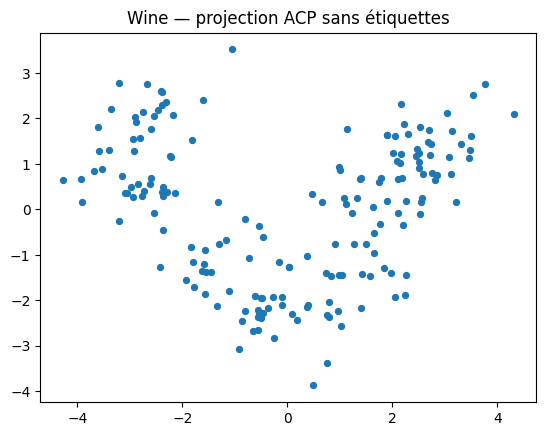

In [39]:
from sklearn.decomposition import PCA
modele = PCA(n_components=3, random_state=GRAINE).fit(X_clu)
projection = modele.transform(X_clu)
print('Variance expliquée par composante :', np.round(modele.explained_variance_ratio_, 3))
plt.scatter(projection[:, 0], projection[:, 1], s=18)
plt.title('Wine — projection ACP sans étiquettes'); plt.show()

## 22. t-SNE

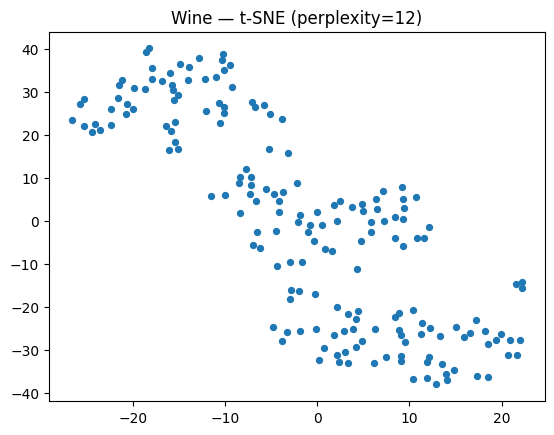

In [40]:
from sklearn.manifold import TSNE
projection = TSNE(n_components=2, perplexity=12, learning_rate='auto', init='pca', random_state=GRAINE).fit_transform(X_clu)
plt.scatter(projection[:, 0], projection[:, 1], s=18)
plt.title('Wine — t-SNE (perplexity=12)'); plt.show()

## 23. UMAP

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


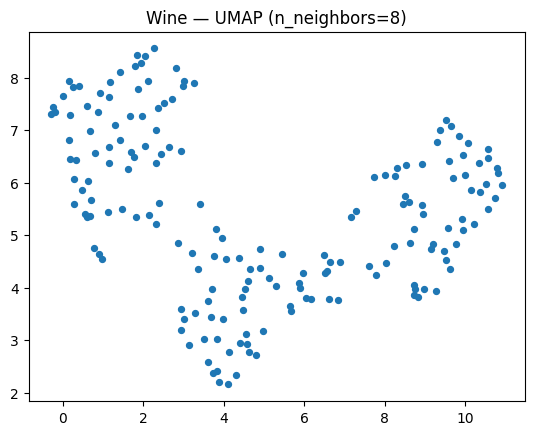

In [44]:
import umap
import matplotlib.pyplot as plt

# Initialisation et affichage UMAP
projection = umap.UMAP(n_components=2, n_neighbors=8, min_dist=0.25, random_state=GRAINE).fit_transform(X_clu)
plt.scatter(projection[:, 0], projection[:, 1], s=18)
plt.title('Wine — UMAP (n_neighbors=8)')
plt.show()

## 24. Isolation Forest

In [43]:
from sklearn.ensemble import IsolationForest
modele = IsolationForest(contamination=.07, n_estimators=120, random_state=GRAINE).fit(X_clu)
etiquettes = modele.predict(X_clu)
print('Observations atypiques :', int((etiquettes == -1).sum()))
print('Attention : atypique ne signifie pas erroné ou frauduleux.')

Observations atypiques : 13
Attention : atypique ne signifie pas erroné ou frauduleux.


## 25. Bandits manchots

In [45]:
# Bandit pédagogique simulé : estimation des probabilités de gain
rng = np.random.default_rng(GRAINE)
probabilites_simulees = np.array([.35, .55, .65, .45])
recompenses = np.zeros(4); nombre_tirages = np.zeros(4)
for etape in range(800):
    bras = etape % 4
    gain = float(rng.random() < probabilites_simulees[bras])
    recompenses[bras] += gain; nombre_tirages[bras] += 1
print('Récompenses moyennes estimées :', np.round(recompenses / nombre_tirages, 3))

Récompenses moyennes estimées : [0.37 0.53 0.63 0.46]


## 26. Epsilon-greedy

In [46]:
# Exploration epsilon-greedy sur le même bandit simulé
rng = np.random.default_rng(GRAINE)
probabilites_simulees = np.array([.35, .55, .65, .45])
recompenses = np.zeros(4); nombre_tirages = np.zeros(4)
epsilon = .2
for etape in range(1500):
    bras = int(rng.integers(4)) if rng.random() < epsilon or not np.all(nombre_tirages) else int(np.argmax(recompenses / np.maximum(nombre_tirages, 1)))
    gain = float(rng.random() < probabilites_simulees[bras])
    recompenses[bras] += gain; nombre_tirages[bras] += 1
print('Fréquences de sélection :', nombre_tirages.astype(int))
print('Valeurs estimées :', np.round(recompenses / np.maximum(nombre_tirages, 1), 3))

Fréquences de sélection : [  83  119 1215   83]
Valeurs estimées : [0.301 0.504 0.653 0.398]


## 27. Q-learning

In [47]:
# Q-learning manuel — environnement CliffWalking (Gymnasium)
import gymnasium as gym
env = gym.make('CliffWalking-v0')
q_table = np.zeros((env.observation_space.n, env.action_space.n))
rng = np.random.default_rng(GRAINE)
for episode in range(1100):
    etat, _ = env.reset(seed=GRAINE + episode)
    epsilon = max(.08, .8 * (1 - episode / 900))
    for pas in range(120):
        action = int(rng.integers(env.action_space.n)) if rng.random() < epsilon else int(np.argmax(q_table[etat]))
        suivant, recompense, termine, tronque, _ = env.step(action)
        cible = recompense + (0 if termine else .95 * np.max(q_table[suivant]))
        q_table[etat, action] += .15 * (cible - q_table[etat, action])
        etat = suivant
        if termine or tronque: break
print('Table Q :', q_table.shape, '| valeur moyenne :', round(q_table.mean(), 2))
env.close()

Table Q : (48, 4) | valeur moyenne : -11.22


## 28. SARSA

In [48]:
# SARSA manuel — même environnement, politique epsilon-greedy suivie
import gymnasium as gym
env = gym.make('CliffWalking-v0')
q_table = np.zeros((env.observation_space.n, env.action_space.n))
rng = np.random.default_rng(GRAINE)
def choisir_action(etat, epsilon):
    return int(rng.integers(env.action_space.n)) if rng.random() < epsilon else int(np.argmax(q_table[etat]))
for episode in range(1100):
    etat, _ = env.reset(seed=GRAINE + episode)
    epsilon = max(.08, .8 * (1 - episode / 900))
    action = choisir_action(etat, epsilon)
    for pas in range(120):
        suivant, recompense, termine, tronque, _ = env.step(action)
        action_suivante = choisir_action(suivant, epsilon)
        cible = recompense + (0 if termine else .95 * q_table[suivant, action_suivante])
        q_table[etat, action] += .15 * (cible - q_table[etat, action])
        etat, action = suivant, action_suivante
        if termine or tronque: break
print('Table Q SARSA :', q_table.shape, '| valeur moyenne :', round(q_table.mean(), 2))
env.close()

Table Q SARSA : (48, 4) | valeur moyenne : -22.51


## 29. DQN — cible conceptuelle

In [49]:
# Cibles DQN : démonstration du calcul de Bellman, SANS réseau neuronal
recompenses = np.array([-1., -100., 0.])
termine = np.array([False, True, False])
meilleure_valeur_suivante = np.array([-3., -2., 5.])
gamma = .9
cibles = recompenses + gamma * (~termine) * meilleure_valeur_suivante
print('Cibles de Bellman calculées :', np.round(cibles, 2))
print('Ce calcul ne constitue pas un entraînement DQN.')

Cibles de Bellman calculées : [  -3.7 -100.     4.5]
Ce calcul ne constitue pas un entraînement DQN.


## Annexes — implémentations manuelles

En complément des modèles intégrés : (1) descente de gradient univariée sur une variable réelle de Diabetes, (2) K-means manuel sur la projection ACP de Wine, (3) Q-learning tabulaire manuel dans l'exemple 27. Les modèles manuels sont à comparer aux références scikit-learn **sur les mêmes données**, si une référence existe.

In [50]:
# Descente de gradient manuelle sur Diabetes (une seule caractéristique)
from sklearn.linear_model import LinearRegression
x = Xr_ent[:, 2].copy()  # Indice de masse corporelle, caractéristique déjà centrée dans le jeu
x = (x - x.mean()) / x.std()
y = yr_ent.copy()
poids, biais, taux = 0., 0., .05
for iteration in range(1800):
    erreur = (poids * x + biais) - y
    poids -= taux * 2 * np.mean(erreur * x)
    biais -= taux * 2 * np.mean(erreur)
reference = LinearRegression().fit(x.reshape(-1, 1), y)
print('Manuel :', round(poids, 3), round(biais, 3))
print('scikit-learn :', round(reference.coef_[0], 3), round(reference.intercept_, 3))


Manuel : 45.974 154.344
scikit-learn : 45.974 154.344


In [51]:
# K-means manuel sur projection ACP du jeu Wine (sans étiquettes)
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
valeurs = PCA(n_components=2, random_state=GRAINE).fit_transform(X_clu)
rng = np.random.default_rng(GRAINE)
centroides = valeurs[rng.choice(len(valeurs), size=3, replace=False)].copy()
for iteration in range(100):
    distances = ((valeurs[:, None, :] - centroides[None, :, :]) ** 2).sum(axis=2)
    groupes = distances.argmin(axis=1)
    nouveaux = np.array([valeurs[groupes == k].mean(axis=0) if np.any(groupes == k) else centroides[k] for k in range(3)])
    if np.allclose(nouveaux, centroides):
        break
    centroides = nouveaux
print('Itérations manuelles :', iteration + 1)
print('Inertie manuelle :', round(((valeurs - centroides[groupes]) ** 2).sum(), 2))
modele_reference = KMeans(n_clusters=3, n_init=10, random_state=GRAINE).fit(valeurs)
print('Inertie scikit-learn :', round(modele_reference.inertia_, 2))
# L'inertie peut différer si l'initialisation est différente.


Itérations manuelles : 3
Inertie manuelle : 260.02
Inertie scikit-learn : 259.51


## Note méthodologique

Les implémentations manuelles complémentaires sont présentées dans les annexes. Q-learning et SARSA sont étudiés dans le même environnement simulé afin de faciliter leur comparaison. Les résultats dépendent notamment de la graine aléatoire, des paramètres retenus et du nombre d’épisodes.